# Data Prep/Setup

## Imports

In [1]:
# Import standard data prep and eda libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd



## Data Sources

### Hatcheries

In [2]:

# # Import from arcgis 
# url = ("https://services9.arcgis.com/6EuFgO4fLTqfNOhu/arcgis/rest/services/"
#        "PA_Hatcheries/FeatureServer/0/query?where=1%3D1&outFields=*&f=geojson")

# hatch = gpd.read_file(url)
# print("First few rows of the hatcheries data:")
# print(hatch.head())
# # Download local copy of hatcheries data
# hatch.to_file("../data/raw/pa_hatcheries.gpkg", driver="GPKG")

# url = "https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_state_500k.zip"
# states = gpd.read_file(url)

# pa = states[states["STUSPS"] == "PA"]

# pa.to_file("../data/raw/pa_boundary.gpkg", driver="GPKG")

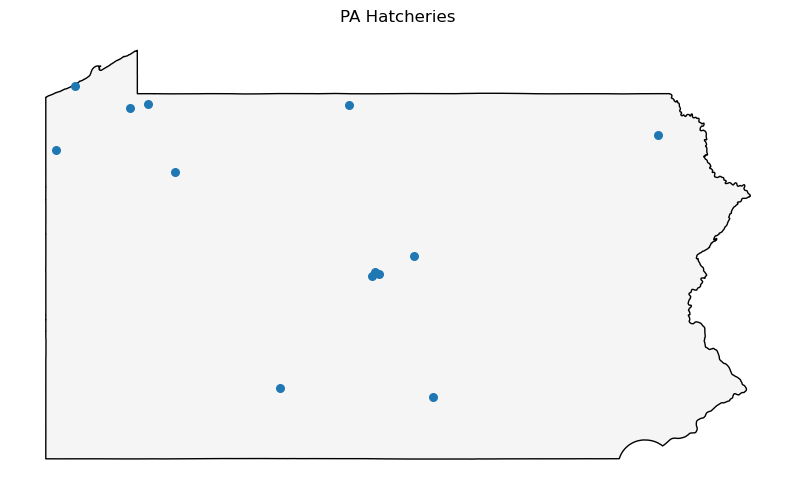

In [3]:

# 1. Load both layers
pa = gpd.read_file("../data/raw/pa_boundary.gpkg")
hatch = gpd.read_file("../data/raw/pa_hatcheries.gpkg")

# 2. Match the CRS (always before overlaying)
hatch = hatch.to_crs(pa.crs)

# 3. Plot
fig, ax = plt.subplots(figsize=(10, 6))
#Basemap
pa.plot(ax=ax, color="whitesmoke", edgecolor="black")
#Hatcheries
hatch.plot(ax=ax, color="tab:blue", markersize=30)

ax.set_title("PA Hatcheries")
ax.set_axis_off()



In [5]:
# Review hatcheries data

hatch.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   REGION      13 non-null     object  
 1   ID          13 non-null     int32   
 2   COUNTY      13 non-null     object  
 3   FULL_NAME   13 non-null     object  
 4   NAME        13 non-null     object  
 5   VISITOR_CE  13 non-null     object  
 6   TROUT       13 non-null     object  
 7   WARM_COOL   13 non-null     object  
 8   STEEL_SALM  13 non-null     object  
 9   Link        13 non-null     object  
 10  Long_       13 non-null     float64 
 11  Lat         13 non-null     float64 
 12  County_Lin  13 non-null     object  
 13  geometry    13 non-null     geometry
dtypes: float64(2), geometry(1), int32(1), object(10)
memory usage: 1.5+ KB


In [11]:
# What does the data look like
print("First few rows of the hatcheries data:")
hatch.head()


First few rows of the hatcheries data:


,REGION,ID,COUNTY,FULL_NAME,NAME,VISITOR_CE,TROUT,WARM_COOL,STEEL_SALM,Link,Long_,Lat,County_Lin,geometry
0,Southcentral,11,Bedford,Reynoldsdale State Fish Hatchery,Reynoldsdale,y,y,,,http://fishandboat.com/Fish/Stocking/StateFish...,-78.58000,40.15750,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-78.58 40.15751)
1,Northcentral,8,Centre,Benner Spring State Fish Hatchery,Benner Spring,,y,y,,http://fishandboat.com/Fish/Stocking/StateFish...,-77.81694,40.85762,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-77.81694 40.85763)
2,Northcentral,9,Centre,Bellefonte State Fish Hatchery,Bellefonte,y,y,,,http://fishandboat.com/Fish/Stocking/StateFish...,-77.79402,40.88273,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-77.79402 40.88274)
3,Northcentral,7,Centre,Pleasant Gap State Fish Hatchery,Pleasant Gap,,y,,,http://fishandboat.com/Fish/Stocking/StateFish...,-77.75750,40.86878,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-77.7575 40.86879)
4,Northcentral,10,Clinton,Tylersville State Fish Hatchery,Tylersville,,y,,,http://fishandboat.com/Fish/Stocking/StateFish...,-77.47062,40.98244,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-77.47062 40.98245)


In [7]:
# Website shows 12 hatcheries with data. How many do we have in our dataset?
print("Number of hatcheries in the dataset:", hatch.shape[0])

# Print out the full list of names to compare to website
print("Names of hatcheries in the dataset:")
print(hatch["FULL_NAME"])

Number of hatcheries in the dataset: 13
Names of hatcheries in the dataset:
0       Reynoldsdale State Fish Hatchery
1      Benner Spring State Fish Hatchery
2         Bellefonte State Fish Hatchery
3       Pleasant Gap State Fish Hatchery
4        Tylersville State Fish Hatchery
5          Huntsdale State Fish Hatchery
6     Pleasant Mount State Fish Hatchery
7             Oswayo State Fish Hatchery
8           Fairview State Fish Hatchery
9              Corry State Fish Hatchery
10        Union City State Fish Hatchery
11        Linesville State Fish Hatchery
12          Tionesta State Fish Hatchery
Name: FULL_NAME, dtype: object


In [15]:
# Does the Trout column y/n explain the one extra? Perhaps a non-trout hatchery?

print("Values in the Trout column:")
non_trout = hatch[hatch["TROUT"] != "y"]
non_trout

Values in the Trout column:


,REGION,ID,COUNTY,FULL_NAME,NAME,VISITOR_CE,TROUT,WARM_COOL,STEEL_SALM,Link,Long_,Lat,County_Lin,geometry
8,Northwest,1,Erie,Fairview State Fish Hatchery,Fairview,,,,y,http://fishandboat.com/Fish/Stocking/StateFish...,-80.27630,42.04262,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-80.2763 42.04263)
10,Northwest,3,Erie,Union City State Fish Hatchery,Union City,,,y,,http://fishandboat.com/Fish/Stocking/StateFish...,-79.81782,41.90750,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-79.81782 41.90751)
12,Northwest,13,Forest,Tionesta State Fish Hatchery,Tionesta,y,,y,y,http://fishandboat.com/Fish/Stocking/StateFish...,-79.44988,41.50756,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-79.44988 41.50757)


*Tionesta* and *Fairview* do not have any production/yield data on the website and has a null for Trout - https://www.pa.gov/agencies/fishandboat/about-us/agency-overview/bureaus/state-fish-hatcheries/tionesta-state-fish-hatchery
https://www.pa.gov/agencies/fishandboat/about-us/agency-overview/bureaus/state-fish-hatcheries/fairview-state-fish-hatchery

Think Union City is just a mussel hatchery. https://www.pa.gov/agencies/fishandboat/about-us/agency-overview/bureaus/field-operations/fisheries-management/union-city-aquatic-conservation-center

Looks like we just need the 10 y Trouts for our project. Side note: interesting scenario where we imagine the three non-trout hatcheries are converted over and see how that changes our run.


In [17]:
# drop the non-trout hatchery from the dataset
hatch_trout = hatch[hatch["TROUT"] == "y"]

In [ ]:
# Review hatcheries that are MORE than just trout hatcheries

mixed_hatcheries =  hatch_trout[(hatch_trout["WARM_COOL"] == "y") | (hatch_trout["STEEL_SALM"] == "y")]
mixed_hatcheries

,REGION,ID,COUNTY,FULL_NAME,NAME,VISITOR_CE,TROUT,WARM_COOL,STEEL_SALM,Link,Long_,Lat,County_Lin,geometry
1,Northcentral,8,Centre,Benner Spring State Fish Hatchery,Benner Spring,,y,y,,http://fishandboat.com/Fish/Stocking/StateFish...,-77.81694,40.85762,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-77.81694 40.85763)
5,Southcentral,12,Cumberland,Huntsdale State Fish Hatchery,Huntsdale,y,y,y,,http://fishandboat.com/Fish/Stocking/StateFish...,-77.30833,40.10306,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-77.30833 40.10307)
6,Northeast,6,Wayne,Pleasant Mount State Fish Hatchery,Pleasant Mount,y,y,y,,http://fishandboat.com/Fish/Stocking/StateFish...,-75.44806,41.73972,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-75.44806 41.73973)
11,Northwest,2,Crawford,Linesville State Fish Hatchery,Linesville,y,y,y,y,http://fishandboat.com/Fish/Stocking/StateFish...,-80.42748,41.64583,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-80.42748 41.64584)


c:\Users\loydg\anaconda3\Lib\site-packages\geopandas\geodataframe.py:1968: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


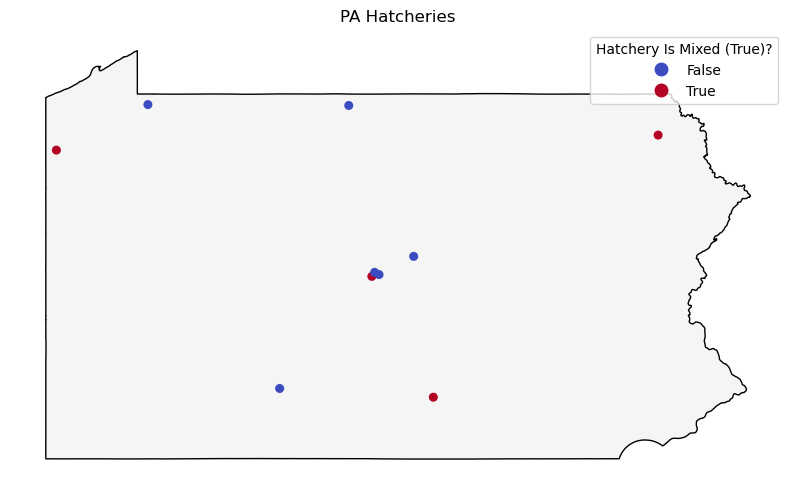

In [29]:
# Show trout only hatcheries versus mixed hatchers on the map (color distinguish)

# Create binary for trout only versus mixed hatcheries
# TRUE = mixed
hatch_trout["MIXED"] = (hatch_trout["WARM_COOL"] == "y") | (hatch_trout["STEEL_SALM"] == "y")

fig, ax = plt.subplots(figsize=(10, 6))
#Basemap
pa.plot(ax=ax, color="whitesmoke", edgecolor="black")

# plot hatch_trout with color distinction for mixed vs trout only
hatch_trout.plot(ax=ax, column="MIXED", cmap="coolwarm", markersize=30, legend=True)

ax.set_title("PA Hatcheries")
ax.set_axis_off()
#add legend title
ax.get_legend().set_title("Hatchery Is Mixed (True)?")